# gpu_corrcal calibration simulation

End-to-end test of the GPU CorrCal likelihood and gradient on simulated data from a CHORD-like array.

1. **Array**: a rectangular grid of 6 m dishes, sorted into exactly redundant baseline groups.
2. **Sky**: a Gaussian random field on a HEALPix map, $C_\ell \propto (1+\ell)^{-2}$, plus a power-law point source population.
3. **Visibilities**: a direct sum over sky pixels and sources,
   $V_{12} = \sum_p A(\hat n_p)\, S_p\, e^{-2\pi i\, \mathbf b_{12}\cdot \hat n_p/\lambda}$, with $\mathbf b_{12} = \mathbf x_2 - \mathbf x_1$.
   Identical beams on an exactly redundant grid mean every baseline in a group sees the same visibility, so only the unique baselines are simulated.
4. **Model covariance**: $\Delta$ from `corrcal.models._compute_diffuse_matrix_from_flat_sky`, $\Sigma$ from the brightest sources, $N$ from the radiometer-style noise level.
5. **Calibration**: inject gains, add noise, minimize the CorrCal negative log-likelihood with scipy CG using the GPU (or CPU reference) `nll` and `grad_nll`.

`DATA_MODE = "direct"` uses the direct-sum visibilities, so the covariance model is only an approximation to the data (flat-sky $\Delta$, unmodeled faint sources, no inter-group correlation).
`DATA_MODE = "model"` draws the diffuse visibilities from $\Delta$ itself. That removes the diffuse model mismatch, so any residual beyond noise and the source-catalog effect points at a bug.

In [2]:
import time
import warnings
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from scipy.optimize import minimize
from scipy.special import j1

from pyuvdata import AiryBeam
from corrcal import models as cc_models   # flat-sky diffuse matrix
from corrcal import utils as cc_utils

warnings.filterwarnings("ignore", category=UserWarning)

try:
    import cupy as cp
    HAVE_CUPY = cp.cuda.runtime.getDeviceCount() > 0
except Exception:
    cp, HAVE_CUPY = None, False
print("CuPy GPU available:", HAVE_CUPY)

CuPy GPU available: True


## Configuration

The full CHORD core is `NX, NY = 22, 24` (512 dishes). That needs `nside = 1024` to resolve the longest fringes at 600 MHz; the direct sum is fast on the GPU and takes about a minute in NumPy. Start smaller to iterate.

In [3]:
BACKEND   = "gpu" if HAVE_CUPY else "cpu"   # likelihood/gradient backend: "gpu" or "cpu"
DATA_MODE = "direct"                        # "direct" (direct-sum sky) or "model" (diffuse drawn from Delta)
SEED      = 1

# Array: CHORD-like grid
NX, NY    = 16, 24         # dishes E-W, N-S  (22, 24 for the full core)
DX, DY    = 6.3, 8.5       # grid spacing [m]
DISH_D    = 6.0            # dish diameter [m]
FREQ      = 600e6          # observing frequency [Hz]

# Grouping
MIN_BL_LEN     = np.sqrt(2) * DISH_D   # drop baselines whose uv footprints overlap the next group strongly
MIN_GROUP_SIZE = 5

# Sky
MAX_ZA_DEG  = 40.0     # sky cap for the direct sum; the 6 m Airy power beam is ~1e-4 by here
T_MEAN      = 30.0     # monopole [K]; enters the autocorrelation only
T_RMS       = 5.0      # rms of the diffuse fluctuations [K]
N_SRC_TOTAL = 2000     # point sources in the cap (~1400/sr above S_MIN)
S_MIN       = 1.0      # [Jy] minimum flux of the source population
SRC_SLOPE   = 2.5      # dN/dS ~ S^-SRC_SLOPE (Euclidean)
N_SRC_CAL   = 5        # brightest (beam-weighted) sources put into Sigma; <= 20 for the GPU kernels

# Noise, gains, solver
SNR          = 1e4     # noise_amp = |V_auto| / SNR, per visibility
AMP_JITTER   = 0.1     # true |g| ~ N(1, AMP_JITTER^2), phases ~ U(0, 2pi)
INIT_AMP_ERR = 0.10    # initial guess: fractional amplitude error
INIT_PHS_ERR = 0.10    # initial guess: phase error [rad]
PHS_NORM     = 0.1     # width of CorrCal's prior on the mean gain phase
GAIN_SCALE   = 1.0

C_LIGHT, K_B = 299792458.0, 1.380649e-23
LAM = C_LIGHT / FREQ
rng = np.random.default_rng(SEED)

## Array layout and redundant groups

384 antennas, 73130 baselines in 711 redundant groups, group sizes 5-368, b_max = 207.4 m


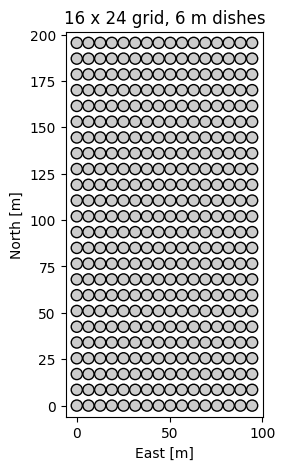

In [4]:
def make_grid(nx, ny, dx, dy):
    E, N = np.meshgrid(np.arange(nx) * dx, np.arange(ny) * dy, indexing="ij")
    antpos = np.stack([E.ravel(), N.ravel(), np.zeros(E.size)], axis=1)
    grid_ij = np.stack(np.meshgrid(np.arange(nx), np.arange(ny), indexing="ij"), -1).reshape(-1, 2)
    return antpos, grid_ij


def make_groups(grid_ij, dx, dy, min_len, min_size):
    # Exactly redundant groups keyed by integer grid offset (di, dj) in the half plane
    # dj > 0 or (dj == 0, di > 0). Each pair is ordered so ant_2 - ant_1 is that offset.
    groups = {}
    n_ant = len(grid_ij)
    for a in range(n_ant):
        for b in range(a + 1, n_ant):
            di, dj = grid_ij[b] - grid_ij[a]
            if dj > 0 or (dj == 0 and di > 0):
                groups.setdefault((di, dj), []).append((a, b))
            else:
                groups.setdefault((-di, -dj), []).append((b, a))

    length = lambda k: np.hypot(k[0] * dx, k[1] * dy)
    keys = sorted((k for k, v in groups.items() if length(k) >= min_len and len(v) >= min_size), key=length)

    ant_1, ant_2, edges = [], [], [0]
    for k in keys:
        for a, b in groups[k]:
            ant_1.append(a)
            ant_2.append(b)
        edges.append(len(ant_1))
    ant_1, ant_2 = np.array(ant_1), np.array(ant_2)
    edges = 2 * np.array(edges)                       # Re/Im-split row edges
    ubl = np.array([[k[0] * dx, k[1] * dy, 0.0] for k in keys])
    grp_of_bl = np.repeat(np.arange(len(keys)), np.diff(edges) // 2)
    return ant_1, ant_2, edges, ubl, grp_of_bl, keys


antpos, grid_ij = make_grid(NX, NY, DX, DY)
ant_1, ant_2, edges, ubl, grp_of_bl, grp_keys = make_groups(grid_ij, DX, DY, MIN_BL_LEN, MIN_GROUP_SIZE)
n_ant, n_bl, n_grp = len(antpos), len(ant_1), len(ubl)

# Every baseline in a group must equal that group's unique baseline.
assert np.allclose(antpos[ant_2] - antpos[ant_1], ubl[grp_of_bl])

b_max = np.linalg.norm(ubl, axis=1).max()
print(f"{n_ant} antennas, {n_bl} baselines in {n_grp} redundant groups, "
      f"group sizes {np.diff(edges).min()//2}-{np.diff(edges).max()//2}, b_max = {b_max:.1f} m")

fig, ax = plt.subplots(figsize=(5, 5))
for x, y, _ in antpos:
    ax.add_patch(plt.Circle((x, y), DISH_D / 2, fc="0.8", ec="k"))
ax.set_xlim(-DISH_D, antpos[:, 0].max() + DISH_D)
ax.set_ylim(-DISH_D, antpos[:, 1].max() + DISH_D)
ax.set_aspect("equal"); ax.set_xlabel("East [m]"); ax.set_ylabel("North [m]")
ax.set_title(f"{NX} x {NY} grid, {DISH_D:.0f} m dishes");

## Sky model

The HEALPix map is treated as already in the local horizon frame (pixel colatitude = zenith angle). For a single snapshot of a statistically isotropic field this is equivalent to any celestial orientation.

The pixel size must resolve the fringe on the longest baseline, $\theta_{\rm pix} < \lambda / (2 b_{\max})$, which sets `nside`. The monopole is subtracted before the direct sum: the Airy power beam's uv footprint has support $|\mathbf u| \le D/\lambda$, and every calibration baseline has $|\mathbf u| \ge \sqrt2 D/\lambda$, so the true monopole response is zero; summing it over a truncated cap would only add an edge artifact.

nside = 1024 (0.057 deg pixels), 1,470,612 pixels in the 40 deg cap, synfast 0.6 s
brightest apparent fluxes [Jy]: [1.83 1.78 1.76 1.52 1.38]; calibration sources hold 36% of the apparent source flux


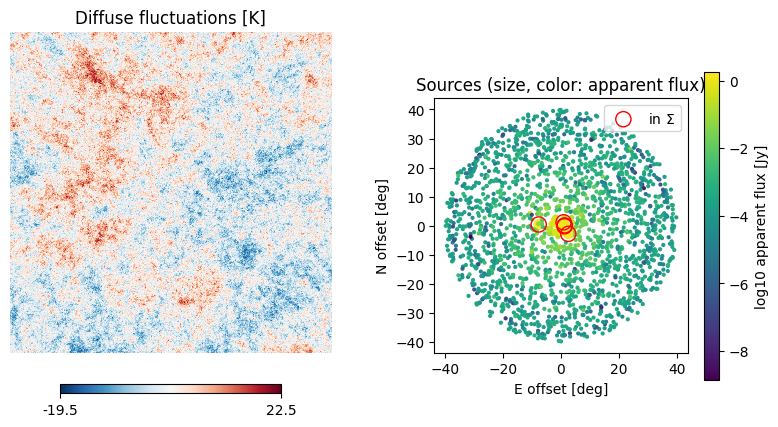

In [5]:
nside = 1 << int(np.ceil(np.log2(np.sqrt(4 * np.pi / 12) / (LAM / (2 * b_max)))))
lmax_map = 3 * nside - 1
pix_area = hp.nside2pixarea(nside)
jy_per_k = 2 * K_B / LAM**2 * 1e26          # [Jy / sr / K]

def airy_power(za):
    x = np.pi * DISH_D * np.sin(za) / LAM
    safe = np.where(x > 1e-12, x, 1.0)
    return np.where(x > 1e-12, (2 * j1(safe) / safe) ** 2, 1.0)

theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
in_cap = theta < np.deg2rad(MAX_ZA_DEG)
pix_za, pix_az = theta[in_cap], phi[in_cap]
pix_nhat = np.array([np.sin(pix_za) * np.cos(pix_az), np.sin(pix_za) * np.sin(pix_az), np.cos(pix_za)])
pix_beam = airy_power(pix_za)

# Diffuse angular power spectrum, normalized so the map rms is T_RMS (no monopole: C_0 = 0).
ells = np.arange(lmax_map + 1.0)
cl_shape = 1.0 / (1.0 + ells) ** 2
cl_shape[0] = 0.0
cl_K = cl_shape * T_RMS**2 / np.sum((2 * ells + 1) / (4 * np.pi) * cl_shape)   # [K^2]

t0 = time.perf_counter()
T_map = hp.synfast(cl_K, nside)               # fluctuations only, mean ~ 0
print(f"nside = {nside} ({np.rad2deg(hp.nside2resol(nside)):.3f} deg pixels), "
      f"{in_cap.sum():,} pixels in the {MAX_ZA_DEG:.0f} deg cap, synfast {time.perf_counter() - t0:.1f} s")

# Point sources: area-uniform in the cap, Pareto fluxes with dN/dS ~ S^-SRC_SLOPE.
cos_za = rng.uniform(np.cos(np.deg2rad(MAX_ZA_DEG)), 1.0, N_SRC_TOTAL)
src_za, src_az = np.arccos(cos_za), rng.uniform(0, 2 * np.pi, N_SRC_TOTAL)
src_nhat = np.array([np.sin(src_za) * np.cos(src_az), np.sin(src_za) * np.sin(src_az), np.cos(src_za)])
src_flux = S_MIN * rng.uniform(size=N_SRC_TOTAL) ** (-1.0 / (SRC_SLOPE - 1.0))
src_app = airy_power(src_za) * src_flux       # beam-weighted (apparent) flux
cal_idx = np.argsort(src_app)[::-1][:N_SRC_CAL]
print(f"brightest apparent fluxes [Jy]: {np.round(src_app[cal_idx], 2)}; "
      f"calibration sources hold {src_app[cal_idx].sum() / src_app.sum():.0%} of the apparent source flux")

fig = plt.figure(figsize=(9, 4))
hp.gnomview(T_map, rot=(0, 90), xsize=600, reso=2 * MAX_ZA_DEG * 60 / 600, fig=fig.number,
            sub=(1, 2, 1), title="Diffuse fluctuations [K]", cmap="RdBu_r", notext=True)
ax = fig.add_subplot(1, 2, 2)
sc = ax.scatter(np.rad2deg(src_za) * np.cos(src_az), np.rad2deg(src_za) * np.sin(src_az),
                s=4 + 40 * src_app / src_app.max(), c=np.log10(src_app), cmap="viridis")
ax.scatter(np.rad2deg(src_za[cal_idx]) * np.cos(src_az[cal_idx]),
           np.rad2deg(src_za[cal_idx]) * np.sin(src_az[cal_idx]), s=120, fc="none", ec="r", label="in $\\Sigma$")
ax.set_aspect("equal"); ax.set_xlabel("E offset [deg]"); ax.set_ylabel("N offset [deg]")
ax.set_title("Sources (size, color: apparent flux)"); ax.legend(loc="upper right")
fig.colorbar(sc, ax=ax, label="log10 apparent flux [Jy]");

## Visibility simulation

`direct_sum` evaluates $V_b = \sum_p w_p\, e^{-2\pi i\, \mathbf b\cdot\hat n_p/\lambda}$ for the unique baselines in pixel chunks. It runs on CuPy when available. Rows of the covariance and data vectors alternate Re/Im, as in CorrCal.

In [6]:
def direct_sum(bl, nhat, weights, chunk=50_000):
    xp = cp if HAVE_CUPY else np
    bl_l = xp.asarray(bl / LAM)
    V = xp.zeros(len(bl), dtype=complex)
    for s in range(0, weights.size, chunk):
        ph = bl_l @ xp.asarray(nhat[:, s:s + chunk])
        V += xp.exp(-2j * np.pi * ph) @ xp.asarray(weights[s:s + chunk])
    return cp.asnumpy(V) if HAVE_CUPY else V


def split_re_im(z):
    out = np.empty(2 * z.size)
    out[0::2], out[1::2] = z.real, z.imag
    return out


t0 = time.perf_counter()
V_diff_u = direct_sum(ubl, pix_nhat, pix_beam * T_map[in_cap] * jy_per_k * pix_area)
V_src_u = direct_sum(ubl, src_nhat, src_app)                  # all sources
V_cal_u = np.stack([direct_sum(ubl, src_nhat[:, [j]], src_app[[j]]) for j in cal_idx], axis=1)
print(f"direct sum: {time.perf_counter() - t0:.1f} s for {n_grp} unique baselines")

# Autocorrelation (zero spacing) including the monopole, for the noise level.
V_auto = np.sum(pix_beam * (T_map[in_cap] + T_MEAN)) * jy_per_k * pix_area + src_app.sum()
print(f"V_auto = {V_auto:.1f} Jy;  rms |V| diffuse = {np.sqrt(np.mean(np.abs(V_diff_u)**2)):.3f} Jy, "
      f"sources = {np.sqrt(np.mean(np.abs(V_src_u)**2)):.3f} Jy")

direct sum: 1.4 s for 711 unique baselines
V_auto = 2885.8 Jy;  rms |V| diffuse = 4.205 Jy, sources = 4.666 Jy


## Model covariance

**Diffuse matrix.** For an exactly redundant group of $n$ baselines with identical beams, the $2n\times 2n$ Re/Im covariance block is $\tfrac{\sigma_r^2}{2}\,\mathbf 1\mathbf 1^T \otimes I_2$, which has rank 2. Its $\Delta$ rows are therefore identical across the group and equal to those of a single baseline. `diffuse_matrix_redundant` calls the flat-sky helper with one representative baseline per group and broadcasts, which gives the same $\Delta\Delta^T$ as the full call at a fraction of the cost (the full call does a dense $2n\times2n$ `eigh` and an $(n_{lm}, n, n)$ harmonic sum per group).

The helper's group band power is $\sum_\ell (2\ell+1) C_\ell\, j_\ell(2\pi|\mathbf u|)^2$, so $C_\ell$ must extend past $2\pi|\mathbf u|_{\max}$; it is extended as $\ell^{-2}$ beyond the map's $\ell_{\max}$.

**Source matrix.** Column $j$ is the Re/Im-split visibility of calibration source $j$ alone, from the same `direct_sum` as the data.

**Units.** Everything is divided by the per-row noise standard deviation, so $N = I$. The likelihood changes by a constant, and the float32 kernels see O(1) numbers.

In [7]:
def diffuse_matrix_redundant(cl_jy, beam, edges, ant_1, ant_2, antpos):
    reps = edges[:-1] // 2                                   # first baseline of each group
    one_edges = 2 * np.arange(len(reps) + 1)
    diff_one = cc_models._compute_diffuse_matrix_from_flat_sky(
        cl_jy, 64, beam, FREQ, antpos, ant_1[reps], ant_2[reps], one_edges,
        n_eig=1, bl_convention="j-i")                        # u = (x_2 - x_1) / lambda, as in direct_sum
    rows = np.repeat(np.arange(len(reps)), np.diff(edges) // 2)
    diff = np.empty((edges[-1], diff_one.shape[1]))
    diff[0::2] = diff_one[2 * rows]
    diff[1::2] = diff_one[2 * rows + 1]
    return diff


lmax_cov = int(np.ceil(2 * np.pi * b_max / LAM * 1.3)) + 50
cl_jy = np.zeros(max(lmax_cov, lmax_map) + 1)
cl_jy[:lmax_map + 1] = cl_K * jy_per_k**2
tail = np.arange(lmax_map + 1, cl_jy.size)
cl_jy[tail] = cl_jy[lmax_map] * ((1.0 + lmax_map) / (1.0 + tail)) ** 2

t0 = time.perf_counter()
diff_mat_jy = diffuse_matrix_redundant(cl_jy, AiryBeam(diameter=DISH_D), edges, ant_1, ant_2, antpos)
src_mat_jy = np.stack([split_re_im(V_cal_u[grp_of_bl, j]) for j in range(N_SRC_CAL)], axis=1)
print(f"Delta {diff_mat_jy.shape}, Sigma {src_mat_jy.shape}, built in {time.perf_counter() - t0:.1f} s")

def normalized_model(snr):
    # noise_amp = |V_auto| / snr is the |V| noise per visibility; each Re or Im row gets noise_amp / sqrt(2).
    sigma_row = (V_auto / snr) / np.sqrt(2)
    return diff_mat_jy / sigma_row, src_mat_jy / sigma_row, sigma_row


diff_mat, src_mat, sigma_row = normalized_model(SNR)
noise = np.ones(edges[-1])

Delta (146260, 2), Sigma (146260, 5), built in 4.0 s


### Check: $\Delta$ against Monte Carlo

Per group, the model predicts $\langle |V_r|^2\rangle = \|\Delta_{\rm Re\,row}\|^2 + \|\Delta_{\rm Im\,row}\|^2$. Averaging $|V_r|^2$ over `N_MC` independent sky realizations through `direct_sum` should give ratios scattered around 1 with fractional scatter $\approx 1/\sqrt{N_{\rm MC}}$. The flat-sky band power and the ignored pixel window bias the ratio at the ~10% level, which is acceptable model mismatch for a covariance. Set `N_MC = 0` to skip.

20 realizations in 22.5 s; MC/model median 0.871, mean 0.893


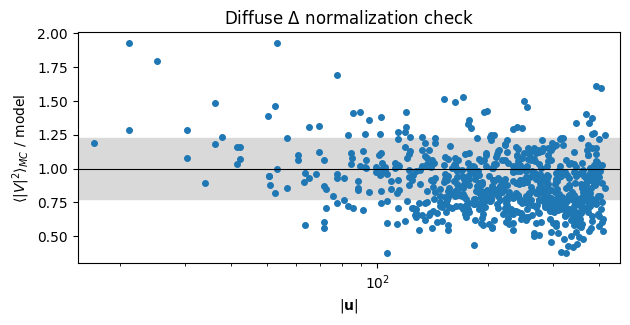

In [8]:
N_MC = 20
if N_MC:
    t0 = time.perf_counter()
    vis_mc = np.array([direct_sum(ubl, pix_nhat, pix_beam * hp.synfast(cl_K, nside)[in_cap] * jy_per_k * pix_area)
                       for _ in range(N_MC)])
    var_mc = np.mean(np.abs(vis_mc) ** 2, axis=0)
    var_model = np.sum(diff_mat_jy[edges[:-1]] ** 2, 1) + np.sum(diff_mat_jy[edges[:-1] + 1] ** 2, 1)
    ratio = var_mc / var_model
    print(f"{N_MC} realizations in {time.perf_counter() - t0:.1f} s; "
          f"MC/model median {np.median(ratio):.3f}, mean {ratio.mean():.3f}")

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.semilogx(np.linalg.norm(ubl, axis=1) / LAM, ratio, "o", ms=4)
    ax.axhline(1, color="k", lw=0.8)
    ax.fill_between([1, 1e4], 1 - 1 / np.sqrt(N_MC), 1 + 1 / np.sqrt(N_MC), color="0.85", zorder=0)
    ax.set_xlim(0.9 * np.linalg.norm(ubl, axis=1).min() / LAM, 1.1 * b_max / LAM)
    ax.set_xlabel(r"$|\mathbf{u}|$"); ax.set_ylabel(r"$\langle|V|^2\rangle_{MC}$ / model")
    ax.set_title(r"Diffuse $\Delta$ normalization check");

## Gains and data

True gains: $|g| \sim \mathcal N(1, 0.1^2)$, phases uniform on $[0, 2\pi)$. The initial guess perturbs them by `INIT_AMP_ERR` and `INIT_PHS_ERR`, as in the CorrCal tutorial. The data are $d_{12} = g_1 g_2^* V_{12} + n_{12}$.

In [9]:
def draw_gains(rng):
    amp = rng.normal(1.0, AMP_JITTER, n_ant)
    phs = rng.uniform(0, 2 * np.pi, n_ant)
    true = amp * np.exp(1j * phs)
    init = amp * rng.normal(1.0, INIT_AMP_ERR, n_ant) * np.exp(1j * (phs + rng.normal(0, INIT_PHS_ERR, n_ant)))
    return true, init


def make_data(true_gains, rng, diff_mat, sigma_row, mode=DATA_MODE):
    if mode == "direct":
        sky = split_re_im(V_diff_u[grp_of_bl] + V_src_u[grp_of_bl]) / sigma_row
    elif mode == "model":
        # Diffuse part drawn from Delta itself: independent N(0, I) amplitudes per group.
        z = rng.standard_normal((n_grp, diff_mat.shape[1]))
        sky = np.einsum("rk,rk->r", diff_mat, z[np.repeat(np.arange(n_grp), np.diff(edges))])
        sky += split_re_im(V_src_u[grp_of_bl]) / sigma_row
    else:
        raise ValueError(mode)
    sky_c = sky[0::2] + 1j * sky[1::2]
    gained = true_gains[ant_1] * np.conj(true_gains[ant_2]) * sky_c
    return split_re_im(gained) + rng.standard_normal(2 * n_bl)   # N = I after normalization


true_gains, init_gains = draw_gains(rng)
data = make_data(true_gains, rng, diff_mat, sigma_row)
print(f"data rows: {data.size}, median |d| / sigma = {np.median(np.abs(data)):.1f}")

data rows: 146260, median |d| / sigma = 15.5


## Calibration

Both backends expose `nll(gains, cov, data, ant_1, ant_2, scale, phs_norm_fac)`. The GPU `grad_nll` additionally takes a `GradWorkspace`, built once per solve. scipy passes the same `args` to `fun` and `jac`, so the two are wrapped in closures.

In [10]:
def to_host(x):
    return cp.asnumpy(x) if (HAVE_CUPY and isinstance(x, cp.ndarray)) else np.asarray(x)


def build_objective(backend, data, diff_mat, src_mat):
    if backend == "gpu":
        from gpu_corrcal.sparse import GpuSparseCov
        from gpu_corrcal.optimize import nll, grad_nll
        from gpu_corrcal.linalg import GradWorkspace
        cov = GpuSparseCov(noise, src_mat, diff_mat, edges, n_eig=diff_mat.shape[1])
        d = cp.ascontiguousarray(cp.asarray(data, dtype=cp.float32))
        a1, a2 = cp.asarray(ant_1, dtype=cp.int32), cp.asarray(ant_2, dtype=cp.int32)
        gws = GradWorkspace(a1, a2, n_ant, cov.n_grp, cov.n_eig, cov.n_src)
        fun = lambda g: float(nll(g, cov, d, a1, a2, GAIN_SCALE, PHS_NORM))
        jac = lambda g: to_host(grad_nll(g, cov, d, a1, a2, GAIN_SCALE, PHS_NORM, gws)).astype(np.float64)
    elif backend == "cpu":
        from corrcal.sparse import SparseCov
        from corrcal.optimize import nll, grad_nll
        cov = SparseCov(noise=noise, src_mat=src_mat, diff_mat=diff_mat, edges=edges,
                        n_eig=diff_mat.shape[1], isinv=False)
        a1, a2 = ant_1.astype(np.int64), ant_2.astype(np.int64)
        fun = lambda g: nll(g, cov, data, a1, a2, GAIN_SCALE, PHS_NORM)
        jac = lambda g: grad_nll(g, cov, data, a1, a2, GAIN_SCALE, PHS_NORM)
    else:
        raise ValueError(backend)
    return fun, jac


def calibrate(backend, data, init_gains, diff_mat, src_mat, maxiter=2000):
    fun, jac = build_objective(backend, data, diff_mat, src_mat)
    x0 = GAIN_SCALE * split_re_im(init_gains)
    t0 = time.perf_counter()
    res = minimize(fun, x0, jac=jac, method="CG", options={"maxiter": maxiter})
    wall = time.perf_counter() - t0
    gains = (res.x[0::2] + 1j * res.x[1::2]) / GAIN_SCALE
    return gains, res, wall


fit_gains, res, wall = calibrate(BACKEND, data, init_gains, diff_mat, src_mat)
print(f"[{BACKEND}] {res.message}  nit={res.nit}  nfev={res.nfev}  njev={res.njev}  "
      f"wall={wall:.2f} s ({1e3 * wall / (res.nfev + res.njev):.2f} ms per call)")

print(BACKEND)

[gpu] Desired error not necessarily achieved due to precision loss.  nit=7  nfev=36  njev=27  wall=0.96 s (15.20 ms per call)
gpu


## Results

Gains are compared after rephasing both sets to antenna 0. CorrCal leaves an overall amplitude and a linear phase gradient across the array poorly constrained when the source catalog is incomplete (Pascua, Sievers & Liu 2026, Sec. 5.4). `degenerate_fit` removes the best-fit $\ln|g|$ offset and phase plane $\phi_0 + \mathbf k\cdot\mathbf x$ from $g_{\rm fit}/g_{\rm true}$; the remainder is the non-degenerate calibration error.

amplitude offset +1.41e-02, phase slope (E, N) = [-4.14752988e-05  1.55109460e-04] rad/m
rms after removing degenerate modes: amp 1.36e-03 (init 9.56e-02), phase 1.22e-03 rad (init 1.02e-01)


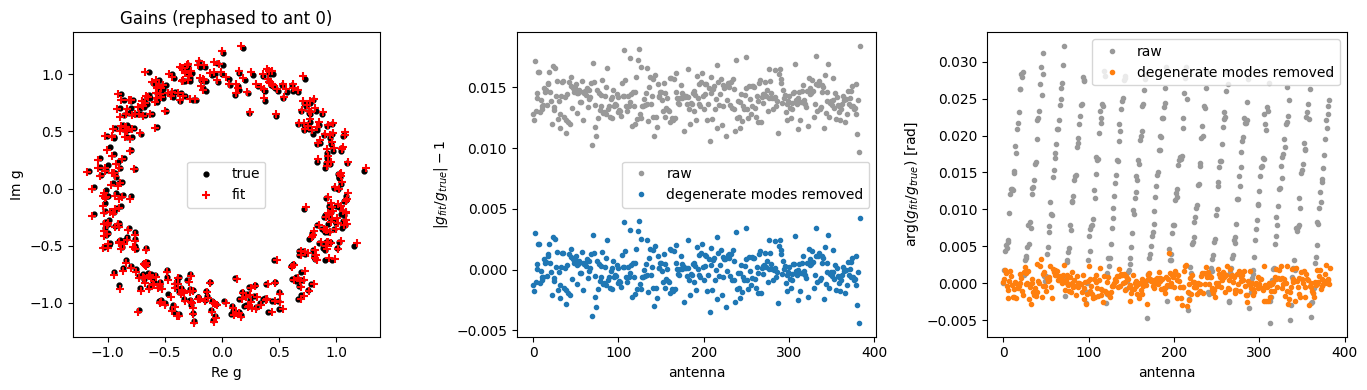

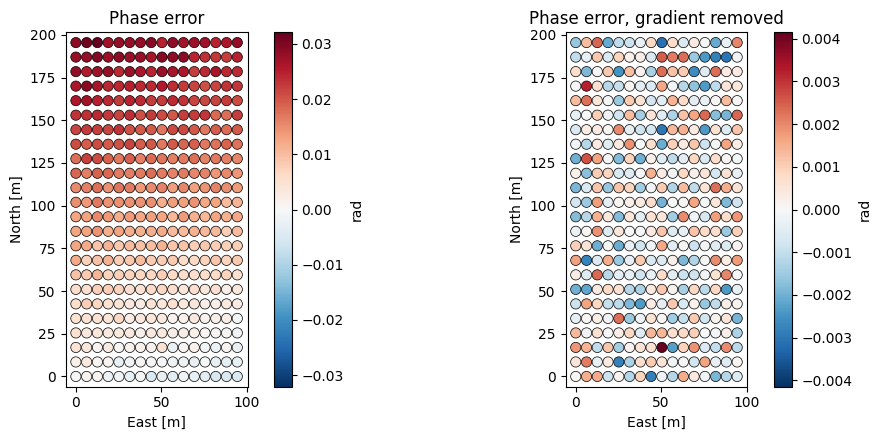

In [11]:
def degenerate_fit(fit, true, antpos):
    r = cc_utils.rephase_to_ant(fit, 0) / cc_utils.rephase_to_ant(true, 0)
    log_amp, phs = np.log(np.abs(r)), np.angle(r)
    A = np.column_stack([np.ones(len(r)), antpos[:, 0], antpos[:, 1]])
    coef, *_ = np.linalg.lstsq(A, phs, rcond=None)
    return {
        "amp_raw": np.abs(r) - 1, "phs_raw": phs,
        "amp_res": np.exp(log_amp - log_amp.mean()) - 1, "phs_res": phs - A @ coef,
        "amp_offset": np.exp(log_amp.mean()) - 1, "phs_slope": coef[1:],
    }


err = degenerate_fit(fit_gains, true_gains, antpos)
err0 = degenerate_fit(init_gains, true_gains, antpos)
rms = lambda x: np.sqrt(np.mean(x ** 2))
print(f"amplitude offset {err['amp_offset']:+.2e}, phase slope (E, N) = {err['phs_slope']} rad/m")
print(f"rms after removing degenerate modes: amp {rms(err['amp_res']):.2e} (init {rms(err0['amp_res']):.2e}), "
      f"phase {rms(err['phs_res']):.2e} rad (init {rms(err0['phs_res']):.2e})")

g_t = cc_utils.rephase_to_ant(true_gains, 0)
g_f = cc_utils.rephase_to_ant(fit_gains, 0)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(g_t.real, g_t.imag, c="k", s=12, label="true")
axes[0].scatter(g_f.real, g_f.imag, marker="+", c="r", s=40, label="fit")
axes[0].set_aspect("equal"); axes[0].legend(); axes[0].set_title("Gains (rephased to ant 0)")
axes[0].set_xlabel("Re g"); axes[0].set_ylabel("Im g")

axes[1].plot(err["amp_raw"], ".", c="0.6", label="raw")
axes[1].plot(err["amp_res"], ".", c="C0", label="degenerate modes removed")
axes[1].set_xlabel("antenna"); axes[1].set_ylabel(r"$|g_{fit}/g_{true}| - 1$"); axes[1].legend()

axes[2].plot(err["phs_raw"], ".", c="0.6", label="raw")
axes[2].plot(err["phs_res"], ".", c="C1", label="degenerate modes removed")
axes[2].set_xlabel("antenna"); axes[2].set_ylabel(r"arg$(g_{fit}/g_{true})$ [rad]"); axes[2].legend()
fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, key, title in zip(axes, ["phs_raw", "phs_res"], ["Phase error", "Phase error, gradient removed"]):
    v = np.abs(err[key]).max()
    dishes = PatchCollection([plt.Circle((x, y), DISH_D / 2) for x, y, _ in antpos],
                             cmap="RdBu_r", edgecolor="k", linewidth=0.5)
    dishes.set_array(err[key]); dishes.set_clim(-v, v)
    ax.add_collection(dishes)
    ax.set_xlim(-DISH_D, antpos[:, 0].max() + DISH_D); ax.set_ylim(-DISH_D, antpos[:, 1].max() + DISH_D)
    ax.set_aspect("equal"); ax.set_xlabel("East [m]"); ax.set_ylabel("North [m]"); ax.set_title(title)
    fig.colorbar(dishes, ax=ax, label="rad")
fig.tight_layout();

## GPU vs CPU on identical data

Runs only when both backends are available. The two solutions should agree to the float32 precision of the GPU kernels, after the same rephasing. The CPU solve is slow beyond a few hundred antennas.

In [12]:
RUN_COMPARISON = HAVE_CUPY and n_ant <= 256
if RUN_COMPARISON:
    other = "cpu" if BACKEND == "gpu" else "gpu"
    fit_o, res_o, wall_o = calibrate(other, data, init_gains, diff_mat, src_mat)
    dg = np.abs(cc_utils.rephase_to_ant(fit_o, 0) - cc_utils.rephase_to_ant(fit_gains, 0))
    print(f"[{other}] nit={res_o.nit} wall={wall_o:.2f} s;  [{BACKEND}] nit={res.nit} wall={wall:.2f} s")
    print(f"max |g_gpu - g_cpu| = {dg.max():.2e}, median {np.median(dg):.2e}")

In [13]:
from corrcal.sparse import SparseCov
from corrcal.optimize import nll as c_nll, grad_nll as c_grad

f_g, j_g = build_objective("gpu", data, diff_mat, src_mat)
f_c, j_c = build_objective("cpu", data, diff_mat, src_mat)
x_cpu = split_re_im(fit_gains if BACKEND == "cpu" else fit_o)
x_gpu = split_re_im(fit_o if BACKEND == "cpu" else fit_gains)
x0 = split_re_im(init_gains)

# 1. Which solution is better under the float64 CPU likelihood?
print("CPU nll at CPU sol:", f_c(x_cpu), "  at GPU sol:", f_c(x_gpu), "  at x0:", f_c(x0))

# 2. Do the backends agree on the gradient, far from and near the optimum?
for name, x in [("x0", x0), ("CPU sol", x_cpu)]:
    gg, gc = j_g(x), j_c(x)
    print(f"{name}: |grad_cpu|max={np.abs(gc).max():.3e}  "
          f"max|grad_gpu-grad_cpu|={np.abs(gg - gc).max():.3e}")

# 3. Is the GPU gradient consistent with the GPU nll? (central difference along a random direction)
v = np.random.default_rng(0).standard_normal(x0.size); v /= np.linalg.norm(v)
for h in [1e-2, 1e-3, 1e-4]:
    fd = (f_g(x0 + h * v) - f_g(x0 - h * v)) / (2 * h)
    print(f"h={h:.0e}: FD={fd:.4e}  grad.v={j_g(x0) @ v:.4e}  (CPU grad.v={j_c(x0) @ v:.4e})")

NameError: name 'fit_o' is not defined

## Residual vs SNR

Repeats the solve over noise and gain realizations at several SNRs, with the sky fixed. Without model mismatch (`DATA_MODE = "model"`, all sources in $\Sigma$) the non-degenerate residual should scale as $1/\mathrm{SNR}$; in `"direct"` mode it flattens onto a floor set by the diffuse-model and source-catalog mismatch.

In [ ]:
SNR_LIST, N_REAL = [1e2, 3e2, 1e3, 3e3, 1e4], 3
RUN_SWEEP = True
if RUN_SWEEP:
    sweep_rng = np.random.default_rng(SEED + 100)
    amp_rms = np.zeros((len(SNR_LIST), N_REAL))
    phs_rms = np.zeros_like(amp_rms)
    t0 = time.perf_counter()
    for i, snr in enumerate(SNR_LIST):
        dm, sm, sr = normalized_model(snr)
        for k in range(N_REAL):
            tg, ig = draw_gains(sweep_rng)
            fg, _, _ = calibrate(BACKEND, make_data(tg, sweep_rng, dm, sr), ig, dm, sm)
            e = degenerate_fit(fg, tg, antpos)
            amp_rms[i, k], phs_rms[i, k] = rms(e["amp_res"]), rms(e["phs_res"])
    print(f"sweep: {len(SNR_LIST) * N_REAL} solves in {time.perf_counter() - t0:.1f} s")
    for s_, a_, p_ in zip(SNR_LIST, amp_rms.mean(1), phs_rms.mean(1)):
        print(f"  SNR {s_:8.0f}:  amp rms {a_:.2e}   phase rms {p_:.2e} rad")

    snr = np.array(SNR_LIST)
    fig, ax = plt.subplots(figsize=(6, 4))
    for vals, lab, c in [(amp_rms, "amplitude (fractional)", "C0"), (phs_rms, "phase [rad]", "C1")]:
        ax.errorbar(snr, vals.mean(1), yerr=vals.std(1), fmt="o-", c=c, capsize=3, label=lab)
    ref = phs_rms.mean(1)[0] * snr[0] / snr
    ax.loglog(snr, ref, "k--", lw=0.8, label=r"$\propto 1/\mathrm{SNR}$")
    ax.set_xlabel("SNR per visibility"); ax.set_ylabel("rms gain error, degenerate modes removed")
    ax.set_title(f"{n_ant} antennas, DATA_MODE = {DATA_MODE!r}, backend = {BACKEND}"); ax.legend();

In [ ]:
SNR_LIST, N_REAL = [1e2, 3e2, 1e3, 3e3, 1e4, 3e4, 1e5], 3
shape = (len(SNR_LIST), N_REAL)
err = {b: np.zeros(shape) for b in ("cpu", "gpu")}   # vs truth, phase rms [rad]
gap = np.zeros(shape)                                # GPU vs CPU, phase rms [rad]
rng_s = np.random.default_rng(SEED + 200)

for i, snr in enumerate(SNR_LIST):
    dm, sm, sr = normalized_model(snr)
    for k in range(N_REAL):
        tg, ig = draw_gains(rng_s)
        d = make_data(tg, rng_s, dm, sr)          # one dataset, used by both backends
        sol = {}
        for b in ("cpu", "gpu"):
            sol[b], _, _ = calibrate(b, d, ig, dm, sm)
            err[b][i, k] = rms(degenerate_fit(sol[b], tg, antpos)["phs_res"])
        gap[i, k] = rms(degenerate_fit(sol["gpu"], sol["cpu"], antpos)["phs_res"])

snr = np.array(SNR_LIST)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(snr, err["cpu"].mean(1), "o-", label="CPU vs truth")
ax.loglog(snr, err["gpu"].mean(1), "s--", label="GPU vs truth")
ax.loglog(snr, gap.mean(1), "^-", label="GPU vs CPU")
ax.set_xlabel("SNR per visibility"); ax.set_ylabel("rms phase error, degenerate modes removed [rad]")
ax.legend();